## Surface Roughness (UAV Lidar DEM)
### Roughness = standard deviation of elevation within a moving window. (Alternative metric available: max elevation range in window.)

#### CRS: EPSG:25832.

In [44]:
# USER CONFIGURATION

DEM_PATH    = "data/dem_2026.tif"
OUTPUT_PATH = "output/roughness_2026.tif"
WINDOW_SIZE = 3          # odd number: 3, 5, 7 ...
METHOD      = "std"      # "std" (elevation std) or "range" (max-min)

In [45]:
# Import required Libraries and read DEM file

import numpy as np
import matplotlib.pyplot as plt
from scipy import ndimage
from dem_utils import read_dem, write_raster

dem, profile, (res_x, res_y) = read_dem(DEM_PATH)
print(f"DEM shape: {dem.shape}, pixel size: {res_x} x {res_y} m")

DEM shape: (1546, 1322), pixel size: 0.25 x 0.25 m


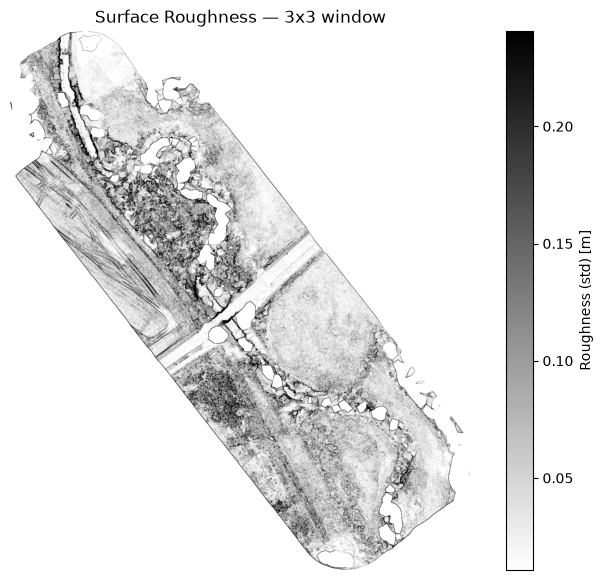

In [46]:
# Compute roughness

def compute_roughness(dem, window=3, method="std"):
    """NaN-aware moving-window roughness."""
    mask = np.isnan(dem)
    filled = np.where(mask, np.nanmean(dem), dem)

    if method == "std":
        mean = ndimage.uniform_filter(filled, size=window)
        mean_sq = ndimage.uniform_filter(filled**2, size=window)
        var = np.maximum(mean_sq - mean**2, 0)
        rough = np.sqrt(var)
    elif method == "range":
        mx = ndimage.maximum_filter(filled, size=window)
        mn = ndimage.minimum_filter(filled, size=window)
        rough = mx - mn
    else:
        raise ValueError("method must be 'std' or 'range'")

    rough[mask] = np.nan
    return rough

roughness = compute_roughness(dem, WINDOW_SIZE, METHOD)

# Visualize result

vmin = np.nanpercentile(roughness, 2)
vmax = np.nanpercentile(roughness, 98)

plt.figure(figsize=(9, 7))
im = plt.imshow(roughness, cmap="gray_r", vmin=vmin, vmax=vmax)
plt.colorbar(im, label=f"Roughness ({METHOD}) [m]")
plt.title(f"Surface Roughness — {WINDOW_SIZE}x{WINDOW_SIZE} window")
plt.axis("off")
plt.show()

In [47]:
# Save roughness to output file
write_raster(OUTPUT_PATH, roughness, profile)

Saved: output/roughness_2026.tif
